# 06 · Preguntas de negocio con SQL

Las tablas limpias del notebook 03 se cargan en una base de datos **SQLite** (viene con Python: no hay que instalar nada y la base es un único archivo). Cada pregunta se responde con una consulta SQL; el resultado vuelve a pandas para mostrarlo o dibujarlo, y se compara con el resultado de pandas del notebook 05 para comprobar que coinciden.

La base de datos se guarda en `data/interno/beira.db`, fuera de GitHub, porque los contratos llevan nombres de proveedores.

Al final se exporta todo a **MySQL** para trabajar en **MySQL Workbench**: el notebook escribe `data/interno/beira_mysql.sql` (crea la base `beira` con las tablas, sus claves y los datos) y las mismas consultas están en `sql/consultas_beira.sql`.

> **Cómo leer este notebook.** Antes de cada celda de código hay un bloque **Cómo funciona**: qué hace la celda, por qué se hace así y qué herramientas usa. Cuando algo no se ha visto en clase, se marca como **Nuevo** y se explica con más calma. Las funciones que se llaman (`recoleccion.…`, `cleaning.…`, `analisis.…`) están en la carpeta `src/`, con su explicación en el docstring.

**Cómo funciona**

- **Qué hace:** prepara el notebook: módulos (`base_datos` para SQL, `graficos`), configuración y la ruta de la base de datos.
- **Por qué así:** la base va a `data/interno/` porque los contratos llevan nombres de proveedores.
- **Herramientas:** `import`, `pathlib.Path`.
- **Nuevo (no visto en clase):** `importlib.reload`.

In [1]:
import importlib
import sys
from pathlib import Path

import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(RAIZ))

from src import base_datos, graficos, recoleccion

for modulo in (base_datos, graficos, recoleccion):
    importlib.reload(modulo)

config = recoleccion.cargar_config(RAIZ / "config.yaml")
RUTA_CLEAN = RAIZ / config["rutas"]["clean"]
RUTA_INTERNO = RAIZ / config["rutas"]["interno"]
RUTA_DB = RUTA_INTERNO / "beira.db"
graficos.estilo_beira()

## 1. Crear la base de datos

Cuatro tablas. De los contratos y las organizaciones solo se cargan las columnas que usan las consultas.

**Cómo funciona**

- **Qué hace:** lee las tablas limpias y crea la base SQLite con cuatro tablas: municipios, contratos, organizaciones y anuncios.
- **Por qué así:** SQLite viene con Python y la base es un solo archivo. `to_sql(if_exists="replace")` crea cada tabla a partir de un DataFrame y la rehace si ya existe. Solo se cargan las columnas que usan las consultas.
- **Herramientas:** `read_csv`, selección de columnas con una lista.
- **Nuevo (no visto en clase):** `sqlite3` y `to_sql`. En clase se usa MySQL; las consultas son el mismo SQL.

In [2]:
municipios = pd.read_csv(RUTA_CLEAN / "municipios.csv")
contratos = pd.read_csv(RUTA_INTERNO / "contratos_ropa_region.csv", low_memory=False)[
    ["idcontrato", "ano", "mes", "fecha", "precio", "municipio", "tipo_comprador", "comprador_nif",
     "proveedor_id", "tipo_proveedor", "producto", "tipoprocedimento"]
]
organizaciones = pd.read_csv(RUTA_CLEAN / "leads_organizaciones.csv", dtype={"telefono": str})[
    ["nombre", "segmento", "municipio", "freguesia", "email", "telefono", "web", "km_a_la_base", "origen"]
]
anuncios = pd.read_csv(RUTA_INTERNO / "anuncios_ropa_region.csv")

filas = base_datos.crear_base(RUTA_DB, {
    "municipios": municipios, "contratos": contratos, "organizaciones": organizaciones, "anuncios": anuncios,
})
filas

{'municipios': 66, 'contratos': 485, 'organizaciones': 1596, 'anuncios': 110}

## 2. Cuándo compran las autarquías (H1)

`GROUP BY` agrupa los contratos por año y mes; `SUM` suma el gasto de cada grupo y `COUNT(*)` cuenta los contratos.

**Cómo funciona**

- **Qué hace:** calcula con SQL el gasto y los contratos de las autarquías por año y mes, lleva el resultado a pandas para el mapa de calor y comprueba que el total coincide con pandas.
- **Por qué así:** el `assert` demuestra que SQL y pandas dan el mismo resultado: es una comprobación cruzada.
- **Herramientas:** `SELECT`, `WHERE … IN`, `GROUP BY`, `ORDER BY`, `pivot`, `assert`.

Contratos: 265 · gasto: 4,916,623 €


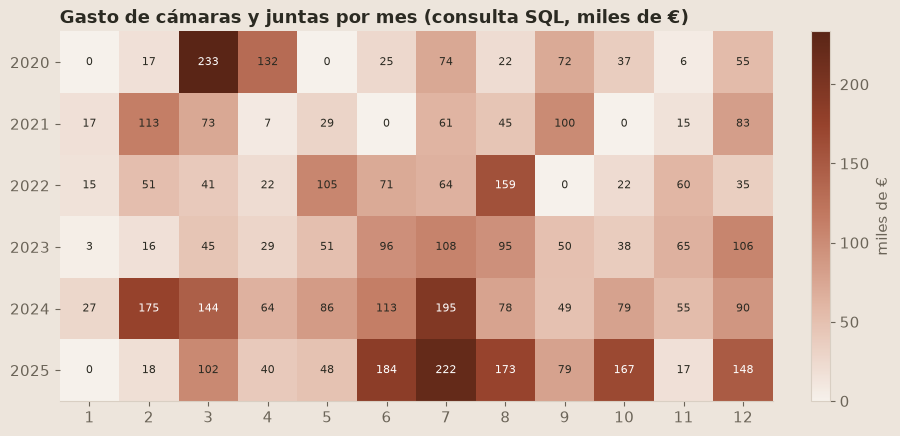

In [3]:
sql = '''
SELECT ano, mes, COUNT(*) AS contratos, ROUND(SUM(precio)) AS gasto
FROM contratos
WHERE tipo_comprador IN ('camara', 'junta')
GROUP BY ano, mes
ORDER BY ano, mes;
'''
por_mes = base_datos.consultar(RUTA_DB, sql)
tabla = por_mes.pivot(index="ano", columns="mes", values="gasto").fillna(0).reindex(columns=range(1, 13), fill_value=0) / 1000
fig = graficos.mapa_calor(tabla, "Gasto de cámaras y juntas por mes (consulta SQL, miles de €)", "miles de €")

# Comprobación: el total coincide con pandas
autarquias = contratos[contratos["tipo_comprador"].isin(["camara", "junta"])]
assert abs(por_mes["gasto"].sum() - autarquias["precio"].sum()) < 100, "SQL y pandas no coinciden"
print("Contratos:", por_mes["contratos"].sum(), "· gasto:", f"{por_mes['gasto'].sum():,.0f} €")

## 3. Dónde se gasta más por habitante

`JOIN` une cada contrato con su municipio para dividir el gasto entre la población. `LIMIT 10` se queda con los diez primeros.

**Cómo funciona**

- **Qué hace:** une contratos y municipios con `JOIN` para calcular el gasto por habitante y se queda con los diez primeros.
- **Por qué así:** el gasto total favorece a los municipios grandes; dividir por la población permite comparar.
- **Herramientas:** `JOIN … ON`, `SUM`, `ROUND`, `LIMIT`.

,municipio,poblacion,contratos,gasto,gasto_por_habitante
0,Sernancelhe,4874,8,230882.0,47.37
1,São João da Pesqueira,6557,6,206090.0,31.43
2,Belmonte,6076,7,169449.0,27.89
3,Armamar,5460,2,126300.0,23.13
4,Pinhel,8009,9,181384.0,22.65
5,Cinfães,17626,10,335144.0,19.01
6,Vila Nova de Foz Côa,5837,3,106034.0,18.17
7,Oleiros,4468,4,76467.0,17.11
8,Moimenta da Beira,9639,3,158048.0,16.40
9,Trancoso,8029,4,113862.0,14.18


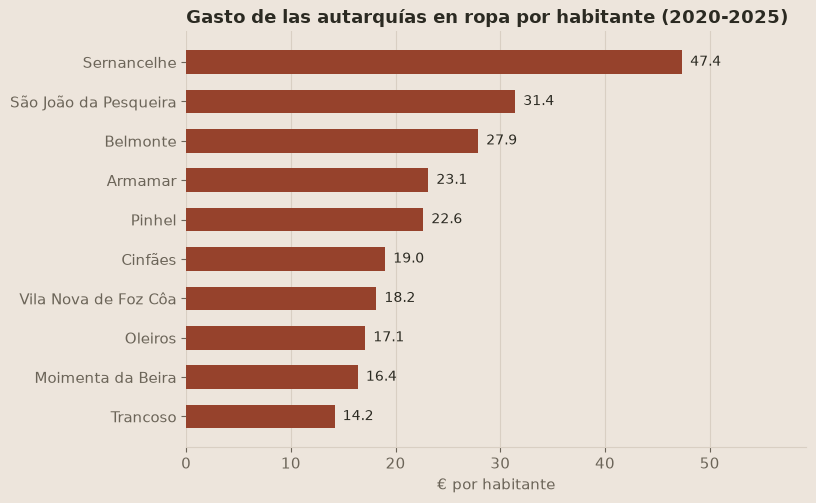

In [4]:
sql = '''
SELECT m.municipio,
       m.poblacion,
       COUNT(*) AS contratos,
       ROUND(SUM(c.precio)) AS gasto,
       ROUND(SUM(c.precio) / m.poblacion, 2) AS gasto_por_habitante
FROM contratos AS c
JOIN municipios AS m ON c.municipio = m.municipio
WHERE c.tipo_comprador IN ('camara', 'junta')
GROUP BY m.municipio, m.poblacion
ORDER BY gasto_por_habitante DESC
LIMIT 10;
'''
gasto_hab = base_datos.consultar(RUTA_DB, sql)
display(gasto_hab)
fig = graficos.barras_horizontales(gasto_hab.set_index("municipio")["gasto_por_habitante"],
                                   "Gasto de las autarquías en ropa por habitante (2020-2025)", "€ por habitante", formato="{:.1f}")
graficos.guardar(fig, "sql_gasto_por_habitante")

## 4. Proveedores (H2)

`WITH` crea una tabla temporal (el gasto de cada proveedor). Después se cuentan los proveedores y, con una subconsulta ordenada y limitada a 10, se calcula qué parte del gasto se llevan los diez mayores.

**Cómo funciona**

- **Qué hace:** cuenta los proveedores y calcula qué parte del gasto se llevan los 3 y los 10 mayores.
- **Por qué así:** `WITH` crea una tabla temporal con el gasto de cada proveedor; las subconsultas ordenan esa tabla, se quedan con los mayores y suman su gasto. El `assert` compara el número de proveedores con pandas.
- **Herramientas:** `WITH`, subconsultas, `ORDER BY … LIMIT`.

In [5]:
sql = '''
WITH por_proveedor AS (
    SELECT proveedor_id, SUM(precio) AS gasto
    FROM contratos
    WHERE tipo_comprador IN ('camara', 'junta')
    GROUP BY proveedor_id
)
SELECT COUNT(*) AS proveedores,
       ROUND(100.0 * (SELECT SUM(gasto) FROM (SELECT gasto FROM por_proveedor ORDER BY gasto DESC LIMIT 3)) / SUM(gasto), 1) AS pct_3_mayores,
       ROUND(100.0 * (SELECT SUM(gasto) FROM (SELECT gasto FROM por_proveedor ORDER BY gasto DESC LIMIT 10)) / SUM(gasto), 1) AS pct_10_mayores
FROM por_proveedor;
'''
proveedores = base_datos.consultar(RUTA_DB, sql)
assert proveedores.loc[0, "proveedores"] == autarquias["proveedor_id"].nunique(), "SQL y pandas no coinciden"
proveedores

,proveedores,pct_3_mayores,pct_10_mayores
0,150,14.9,32.1


## 5. Contacto público por segmento (H3)

`CASE WHEN` convierte cada fila en 1 (tiene email) o 0 (no tiene); la media de esos unos y ceros es el porcentaje.

**Cómo funciona**

- **Qué hace:** calcula el % de organizaciones con email y con teléfono por segmento.
- **Por qué así:** `CASE WHEN` convierte cada fila en 1 (tiene el dato) o 0; la media (`AVG`) de unos y ceros es el porcentaje. Solo cuenta OpenStreetMap (sin las juntas añadidas).
- **Herramientas:** `CASE WHEN`, `AVG`, `GROUP BY`.

In [6]:
sql = '''
SELECT segmento,
       COUNT(*) AS organizaciones,
       ROUND(100.0 * AVG(CASE WHEN email IS NOT NULL THEN 1 ELSE 0 END), 1) AS pct_email,
       ROUND(100.0 * AVG(CASE WHEN telefono IS NOT NULL THEN 1 ELSE 0 END), 1) AS pct_telefono
FROM organizaciones
WHERE origen = 'OpenStreetMap'
GROUP BY segmento
ORDER BY organizaciones DESC;
'''
contacto = base_datos.consultar(RUTA_DB, sql)
osm = organizaciones[organizaciones["origen"] == "OpenStreetMap"]
assert contacto["organizaciones"].sum() == len(osm), "SQL y pandas no coinciden"
contacto

,segmento,organizaciones,pct_email,pct_telefono
0,escuela,809,80.2,84.8
1,autarquia,304,5.6,9.9
2,instalacion_deportiva,189,2.1,9.5
3,bomberos,108,17.6,25.9
4,asociacion,81,6.2,6.2
5,club,61,8.2,9.8


## 6. Quién vuelve a comprar (H5)

`HAVING` filtra después de agrupar: solo los compradores con contratos en dos años distintos o más (`COUNT(DISTINCT ano)`).

**Cómo funciona**

- **Qué hace:** lista las autarquías que compran en dos años distintos o más.
- **Por qué así:** `HAVING` filtra después de agrupar (`WHERE` filtra antes); `COUNT(DISTINCT ano)` cuenta años distintos.
- **Herramientas:** `GROUP BY`, `HAVING`, `COUNT(DISTINCT …)`.

In [7]:
sql = '''
SELECT municipio,
       COUNT(DISTINCT ano) AS anos_con_compras,
       COUNT(*) AS contratos,
       ROUND(SUM(precio)) AS gasto
FROM contratos
WHERE tipo_comprador IN ('camara', 'junta')
GROUP BY comprador_nif, municipio
HAVING COUNT(DISTINCT ano) >= 2
ORDER BY anos_con_compras DESC, gasto DESC;
'''
recurrentes = base_datos.consultar(RUTA_DB, sql)
print("Autarquías que compran en dos años o más:", len(recurrentes))
recurrentes.head(10)

Autarquías que compran en dos años o más: 32


,municipio,anos_con_compras,contratos,gasto
0,Viseu,6,27,616010.0
1,Coimbra,6,27,418343.0
2,Guarda,5,25,459949.0
3,Sernancelhe,5,8,230882.0
4,Coimbra,4,17,256891.0
5,Castelo Branco,4,6,211961.0
6,São João da Pesqueira,4,6,206090.0
7,Pinhel,4,9,181384.0
8,Belmonte,4,7,169449.0
9,Trancoso,4,4,113862.0


## 7. El piloto: organizaciones por segmento y distancia

Se unen las organizaciones con los municipios del piloto (`piloto = 1`) y se separan las que están a 20 km o menos de la base.

**Cómo funciona**

- **Qué hace:** cuenta las organizaciones del piloto por segmento, cuántas están a 20 km o menos y cuántas tienen email.
- **Por qué así:** `SUM(CASE WHEN …)` es un recuento con condición; el `JOIN` con municipios permite filtrar por `piloto = 1`.
- **Herramientas:** `JOIN`, `SUM(CASE WHEN …)`, `WHERE`.

In [8]:
sql = '''
SELECT o.segmento,
       COUNT(*) AS organizaciones,
       SUM(CASE WHEN o.km_a_la_base <= 20 THEN 1 ELSE 0 END) AS a_20_km_o_menos,
       SUM(CASE WHEN o.email IS NOT NULL THEN 1 ELSE 0 END) AS con_email
FROM organizaciones AS o
JOIN municipios AS m ON o.municipio = m.municipio
WHERE m.piloto = 1
GROUP BY o.segmento
ORDER BY organizaciones DESC;
'''
base_datos.consultar(RUTA_DB, sql)

,segmento,organizaciones,a_20_km_o_menos,con_email
0,autarquia,84,29,7
1,escuela,64,54,47
2,instalacion_deportiva,17,11,0
3,bomberos,14,13,5
4,asociacion,13,7,0
5,club,5,5,0


## 8. Concursos públicos anunciados, por año

**Cómo funciona**

- **Qué hace:** resume los concursos públicos anunciados por año: cuántos, cuántos de cámaras y la media de días para presentar propuesta.
- **Por qué así:** sirve para ver si cada año hay más concursos y si el plazo para presentarse cambia.
- **Herramientas:** `COUNT`, `SUM(CASE WHEN …)`, `AVG`.

In [9]:
sql = '''
SELECT ano,
       COUNT(*) AS concursos,
       SUM(CASE WHEN tipo_comprador = 'camara' THEN 1 ELSE 0 END) AS de_camaras,
       ROUND(AVG(dias_para_propuestas)) AS dias_para_propuestas
FROM anuncios
GROUP BY ano
ORDER BY ano;
'''
base_datos.consultar(RUTA_DB, sql)

,ano,concursos,de_camaras,dias_para_propuestas
0,2020,16,2,30.0
1,2021,23,1,33.0
2,2022,14,0,35.0
3,2023,27,2,19.0
4,2024,11,3,16.0
5,2025,19,6,14.0


## 9. Exportar a MySQL (para MySQL Workbench)

Se escribe un script que crea la base `beira` en MySQL con las cuatro tablas, sus claves primarias y las relaciones (cada contrato, organización y anuncio apunta a su municipio). En Workbench:

1. *File > Open SQL Script* y abrir `data/interno/beira_mysql.sql`; ejecutarlo entero (icono del rayo). Al final muestra las filas de cada tabla.
2. Abrir `sql/consultas_beira.sql` y ejecutar cada consulta con el cursor dentro y Ctrl + Enter.
3. Para ver el diagrama de la base: *Database > Reverse Engineer* en Workbench, o la imagen `figuras/diagrama_base_datos.png`.

**Cómo funciona**

- **Qué hace:** escribe `beira_mysql.sql`, un script que crea la base `beira` en MySQL con las cuatro tablas, sus claves primarias, las claves foráneas (cada contrato, organización y anuncio apunta a su municipio) y los datos.
- **Por qué así:** en clase se trabaja con MySQL Workbench; el script permite rehacer la base desde cero con un clic. `exportar_mysql` decide el tipo de cada columna (BIGINT, DOUBLE, DATE, VARCHAR) y escribe los `INSERT` en bloques de 200 filas. A organizaciones se le añade un `id` porque no tiene ninguna columna única.
- **Herramientas:** listas, diccionarios, `rename_axis`, `reset_index`, `assign` con `lambda`.
- **Nuevo (no visto en clase):** generar un script SQL desde Python (claves primarias y foráneas escritas por código).

In [10]:
columnas_municipios = ["municipio", "distrito", "piloto", "poblacion", "poblacion_5_24", "poblacion_65_mas", "pct_5_24",
                       "total_organizaciones", "con_email", "autarquia", "club", "asociacion", "escuela", "bomberos",
                       "instalacion_deportiva", "organizaciones_por_1000_hab", "km_a_la_base", "nombre_festivo", "fecha_2026",
                       "region_nuts3", "ine_vestuario_2022", "ine_impresion_2022", "contratos_autarquias_ropa", "gasto_autarquias_ropa"]
tablas_mysql = {
    "municipios": municipios[[c for c in columnas_municipios if c in municipios.columns]],
    "contratos": contratos,
    "organizaciones": organizaciones.reset_index(drop=True).rename_axis("id").reset_index().assign(id=lambda d: d["id"] + 1),
    "anuncios": anuncios[["IdIncm", "ano", "mes", "fecha", "comprador_nif", "comprador", "tipo_comprador", "municipio",
                          "producto", "modeloAnuncio", "precio_base", "dias_para_propuestas"]],
}
claves = {"municipios": "municipio", "contratos": "idcontrato", "organizaciones": "id", "anuncios": "IdIncm"}
relaciones = {
    "contratos": [("municipio", "municipios", "municipio")],
    "organizaciones": [("municipio", "municipios", "municipio")],
    "anuncios": [("municipio", "municipios", "municipio")],
}
ruta_mysql = RUTA_INTERNO / "beira_mysql.sql"
base_datos.exportar_mysql(tablas_mysql, claves, relaciones, ruta_mysql)

{'municipios': 66, 'contratos': 485, 'organizaciones': 1596, 'anuncios': 110}